# Sensitivity and Anomaly Analysis

## Purpose

This notebook contains supplementary and exploratory analyses conducted after
the original model development and independent evaluation.

These analyses do not modify the original target-engineering procedure,
feature selection, hyperparameter tuning, or final independent test results.

## Important evaluation distinction

Results computed using the full modeling dataset may include training,
validation, and test observations. Such results are descriptive or
exploratory and must not be interpreted as independent out-of-sample
performance.

The independent test period remains January 2024?December 2025.


In [ ]:
import pandas as pd
import numpy as np
import joblib
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load the modeling dataset and saved final Ridge pipeline
df_model = pd.read_csv(
    "../data/processed/mnjoli_water_stress_modeling_dataset.csv",
    parse_dates=["month_date", "forecast_date"]
)

final_ridge = joblib.load("../models/water_stress_ridge.joblib")

# Exact predictors retained by the fitted model
selected_features = list(final_ridge.feature_names_in_)

# Chronological ordering
df_model = df_model.sort_values(
    "forecast_date"
).reset_index(drop=True)

# Independent test period: January 2024-December 2025
test_mask = (
    (df_model["forecast_date"] >= "2024-01-01")
    & (df_model["forecast_date"] <= "2025-12-01")
)

test_df = df_model.loc[test_mask].copy()

# Ridge predictions
ridge_predictions = final_ridge.predict(
    test_df[selected_features]
)

# Persistence baseline: previous month's observed SWBA
persistence_predictions = (
    df_model["target_t_plus_1"].shift(1).loc[test_mask].values
)

# Climatology baseline: zero standardized anomaly
climatology_predictions = np.zeros(len(test_df))

# Independent test results
test_results = pd.DataFrame({
    "forecast_date": test_df["forecast_date"].values,
    "observed": test_df["target_t_plus_1"].values,
    "ridge_forecast": ridge_predictions,
    "persistence": persistence_predictions,
    "climatology": climatology_predictions
})

test_results["residual"] = (
    test_results["observed"] - test_results["ridge_forecast"]
)

test_results["absolute_error"] = (
    test_results["residual"].abs()
)

print("Independent test sample size:", len(test_results))
print("Test period:",
      test_results["forecast_date"].min(), "to",
      test_results["forecast_date"].max())

for name in ["ridge_forecast", "persistence", "climatology"]:
    actual = test_results["observed"]
    predicted = test_results[name]

    print(f"\n{name}")
    print(f"MAE:  {mean_absolute_error(actual, predicted):.4f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(actual, predicted)):.4f}")
    print(f"R2:   {r2_score(actual, predicted):.4f}")


# 1. Temporal Trend Analysis

We estimate the temporal trend in SWBA while controlling for
calendar-month differences. HAC (Newey-West) standard errors with
three lags account for potential autocorrelation and
heteroskedasticity in the monthly residuals.

This is an observational trend analysis. A positive or negative
trend does not, by itself, establish climate-change causation,
declining drought risk, or increasing rainfall.

The full-period estimate is reported first. A separate sensitivity
analysis examines how the estimated trend changes when the extreme
positive May 2024 SWBA observation is excluded. The exclusion is
diagnostic only; it does not replace the full-period estimate.


In [ ]:
import statsmodels.formula.api as smf

# Reconstruct SWBA using the modeling dataset's observed target
trend_data = df_model[
    ["forecast_date", "target_t_plus_1"]
].copy()

trend_data["forecast_date"] = pd.to_datetime(
    trend_data["forecast_date"]
)

trend_data = trend_data.dropna(
    subset=["target_t_plus_1"]
).copy()

trend_data["year_index"] = (
    trend_data["forecast_date"].dt.year
    + (trend_data["forecast_date"].dt.month - 1) / 12
)

trend_data["calendar_month"] = (
    trend_data["forecast_date"].dt.month.astype("category")
)

# HAC/Newey-West regression with calendar-month controls
trend_model = smf.ols(
    "target_t_plus_1 ~ year_index + C(calendar_month)",
    data=trend_data
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 3}
)

print("FULL-PERIOD SWBA TREND WITH CALENDAR-MONTH CONTROLS")
print(trend_model.summary())

slope = trend_model.params["year_index"]
p_value = trend_model.pvalues["year_index"]
ci_low, ci_high = trend_model.conf_int().loc["year_index"]

print(f"\nTrend: {slope:.5f} SWBA units/year")
print(f"HAC p-value: {p_value:.6f}")
print(f"95% HAC confidence interval: [{ci_low:.5f}, {ci_high:.5f}]")

# Diagnostic sensitivity check: exclude the extreme positive May 2024 observation
sensitivity_data = trend_data[
    trend_data["forecast_date"] != pd.Timestamp("2024-05-01")
].copy()

sensitivity_model = smf.ols(
    "target_t_plus_1 ~ year_index + C(calendar_month)",
    data=sensitivity_data
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 3}
)

slope_sens = sensitivity_model.params["year_index"]
p_sens = sensitivity_model.pvalues["year_index"]
ci_sens_low, ci_sens_high = (
    sensitivity_model.conf_int().loc["year_index"]
)

print("\nSENSITIVITY CHECK: EXCLUDING MAY 2024")
print(f"Trend: {slope_sens:.5f} SWBA units/year")
print(f"HAC p-value: {p_sens:.6f}")
print(
    "95% HAC confidence interval: "
    f"[{ci_sens_low:.5f}, {ci_sens_high:.5f}]"
)


# 2. May 2024 Extreme Positive SWBA Anomaly Investigation

This section independently reconstructs the three-month water
balance ending in May 2024 and verifies its standardized anomaly
against the 2015-2021 May reference climatology.

The analysis distinguishes the absolute water balance in
millimetres from the standardized anomaly relative to the
historical calendar-month reference.


In [ ]:
import pandas as pd
import numpy as np

# Load the source CSV
source_path = "../data/processed/mnjoli_water_stress_monthly.csv"

raw = pd.read_csv(source_path, parse_dates=["month_date"])
raw = raw.sort_values("month_date").reset_index(drop=True)

# Reconstruct monthly water balance
raw["water_balance_mm"] = (
    raw["precipitation_mm"] - raw["pet_mm"]
)

# Reconstruct rolling 3-month water balance
raw["water_balance_3month"] = (
    raw["water_balance_mm"]
    .rolling(3, min_periods=3)
    .sum()
)

# Extract training-period May observations
training_may = raw.loc[
    (raw["month_date"] >= "2015-01-01")
    & (raw["month_date"] <= "2021-12-01")
    & (raw["month_date"].dt.month == 5),
    "water_balance_3month"
].dropna()

# Calculate climatology independently
may_mean = training_may.mean()
may_std_sample = training_may.std(ddof=1)
may_std_population = training_may.std(ddof=0)

# Extract May 2024
may_2024_balance = raw.loc[
    raw["month_date"] == "2024-05-01",
    "water_balance_3month"
].iloc[0]

# Recompute standardized anomaly
swba_sample = (
    may_2024_balance - may_mean
) / may_std_sample

swba_population = (
    may_2024_balance - may_mean
) / may_std_population

print("May training sample count:", len(training_may))
print("May training mean:", may_mean)
print("May sample standard deviation:", may_std_sample)
print("May population standard deviation:", may_std_population)
print("May 2024 3-month balance:", may_2024_balance)

print("\nRecalculated May 2024 SWBA:")
print("Using ddof=1:", swba_sample)
print("Using ddof=0:", swba_population)

# Verify the reconstructed SWBA against the modelling dataset target
model_may_swba = df_model.loc[
    df_model["forecast_date"] == pd.Timestamp("2024-05-01"),
    "target_t_plus_1"
].iloc[0]

print("\nModel May 2024 SWBA:", model_may_swba)
print("Reconstructed May 2024 SWBA:", swba_sample)
print("Absolute difference:", abs(swba_sample - model_may_swba))

assert np.isclose(
    swba_sample,
    model_may_swba,
    atol=1e-5
), "May 2024 SWBA reconstruction does not match the model target."

print("PASS: May 2024 SWBA independently reproduced.")


In [2]:

may_values = raw.loc[
    (raw["month_date"] >= "2015-01-01") &
    (raw["month_date"] <= "2021-12-01") &
    (raw["month_date"].dt.month == 5),
    ["month_date", "water_balance_3month"]
].dropna()

print("May training climatology:")
display(may_values)

print("\nDescriptive statistics:")
display(may_values["water_balance_3month"].describe())


May training climatology:


,month_date,water_balance_3month
4,2015-05-01,-447.187622
16,2016-05-01,-361.261941
28,2017-05-01,-387.439747
40,2018-05-01,-323.359013
52,2019-05-01,-320.267087
64,2020-05-01,-356.218182
76,2021-05-01,-390.678056



Descriptive statistics:


count      7.000000
mean    -369.487378
std       43.975093
min     -447.187622
25%     -389.058902
50%     -361.261941
75%     -339.788598
max     -320.267087
Name: water_balance_3month, dtype: float64

In [3]:

may_2024 = raw.loc[
    raw["month_date"] == "2024-05-01",
    ["month_date", "precipitation_mm", "pet_mm",
     "water_balance_mm", "water_balance_3month"]
]

print("May 2024 observation:")
display(may_2024)

print("\nHistorical May range:")
print("Minimum:", may_values["water_balance_3month"].min())
print("Maximum:", may_values["water_balance_3month"].max())

print("\nMay 2024 relative to training:")
print("Training mean:", may_values["water_balance_3month"].mean())
print("May 2024 balance:",
      may_2024["water_balance_3month"].iloc[0])


May 2024 observation:


,month_date,precipitation_mm,pet_mm,water_balance_mm,water_balance_3month
112,2024-05-01,4.239254,138.897173,-134.657919,-58.962463



Historical May range:
Minimum: -447.1876219191233
Maximum: -320.267086546459

May 2024 relative to training:
Training mean: -369.4873784038762
May 2024 balance: -58.96246302334376


In [4]:

raw.loc[
    (raw["month_date"] >= "2024-03-01") &
    (raw["month_date"] <= "2024-05-01"),
    ["month_date", "precipitation_mm", "pet_mm",
     "water_balance_mm", "water_balance_3month"]
]


,month_date,precipitation_mm,pet_mm,water_balance_mm,water_balance_3month
110,2024-03-01,330.118035,180.446340,149.671695,-112.303503
111,2024-04-01,59.422274,133.398513,-73.976239,-56.026364
112,2024-05-01,4.239254,138.897173,-134.657919,-58.962463


In [5]:

# March water-balance values across the full dataset
march_values = raw.loc[
    raw["month_date"].dt.month == 3,
    ["month_date", "precipitation_mm", "pet_mm",
     "water_balance_mm", "water_balance_3month"]
].dropna()

display(march_values)

print("\nMarch precipitation statistics:")
print(march_values["precipitation_mm"].describe())

print("\nMarch 2024 precipitation percentile:")
march_2024_precip = raw.loc[
    raw["month_date"] == "2024-03-01",
    "precipitation_mm"
].iloc[0]

percentile = (
    raw.loc[raw["month_date"].dt.month == 3, "precipitation_mm"]
    .rank(pct=True)
    .loc[raw["month_date"] == "2024-03-01"]
    .iloc[0] * 100
)

print(f"March 2024: {march_2024_precip:.2f} mm")
print(f"Percentile among March observations: {percentile:.1f}%")


,month_date,precipitation_mm,pet_mm,water_balance_mm,water_balance_3month
2,2015-03-01,66.667655,230.976277,-164.308621,-331.496546
14,2016-03-01,73.773743,197.202085,-123.428343,-445.017634
26,2017-03-01,69.400065,205.271218,-135.871153,-276.030771
38,2018-03-01,72.155959,187.807012,-115.651052,-347.872040
50,2019-03-01,83.619651,178.015382,-94.395732,-236.027304
62,2020-03-01,66.461116,181.266116,-114.805000,-281.649361
74,2021-03-01,104.415934,198.256223,-93.840289,50.739020
86,2022-03-01,72.241109,196.673368,-124.432259,-376.089044
98,2023-03-01,79.147793,199.540222,-120.392429,25.664348
110,2024-03-01,330.118035,180.446340,149.671695,-112.303503



March precipitation statistics:
count     11.000000
mean      99.606836
std       77.187827
min       66.461116
25%       70.778012
50%       73.773743
75%       81.383722
max      330.118035
Name: precipitation_mm, dtype: float64

March 2024 precipitation percentile:
March 2024: 330.12 mm
Percentile among March observations: 100.0%


# 3. SWBA Distribution and Dry-Condition Diagnostics

These analyses describe the distribution of SWBA values and the
frequency of dry and extreme conditions across the modeling period.
They are descriptive, not forecasts of event probability.

In [23]:
drought_threshold = -2.0

all_drought = df_model[
    df_model["target_t_plus_1"] <= drought_threshold
]

print("Total extreme drought samples (SWBA <= -2):", len(all_drought))

display(
    all_drought[
        ["forecast_date", "target_t_plus_1"]
    ].sort_values("forecast_date").round(3)
)

Total extreme drought samples (SWBA <= -2): 0


C:\Users\Para\AppData\Local\Temp\ipykernel_16204\2147585904.py:12: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].sort_values("forecast_date").round(3)


,forecast_date,target_t_plus_1


In [24]:
drought_mask = test_results["observed"] <= -2.0

drought_results = test_results.loc[
    drought_mask,
    [
        "observed",
        "ridge_forecast",
        "residual",
        "absolute_error"
    ]
]

print("Extreme drought events (observed SWBA <= -2):")
print("Count:", len(drought_results))

display(drought_results.round(4))

Extreme drought events (observed SWBA <= -2):
Count: 0


,observed,ridge_forecast,residual,absolute_error


In [26]:
print("Test set size:", len(test_results))

print("\nObserved SWBA statistics:")
display(test_results["observed"].describe().round(4))

print("\nMost negative observed SWBA:")
print(test_results["observed"].min())

print("\nNumber of observations <= -1:")
print((test_results["observed"] <= -1.0).sum())

print("\nNumber of observations <= -1.5:")
print((test_results["observed"] <= -1.5).sum())

print("\nNumber of observations <= -2:")
print((test_results["observed"] <= -2.0).sum())

Test set size: 24

Observed SWBA statistics:


count    24.0000
mean      0.7989
std       1.6006
min      -1.0491
25%      -0.0601
50%       0.6437
75%       1.1345
max       7.0614
Name: observed, dtype: float64


Most negative observed SWBA:
-1.049057934742364

Number of observations <= -1:
1

Number of observations <= -1.5:
0

Number of observations <= -2:
0


In [27]:
print("Complete dataset SWBA statistics:")
display(df_model["target_t_plus_1"].describe().round(4))

print("\nExtreme drought samples (<= -2):")
print((df_model["target_t_plus_1"] <= -2.0).sum())

print("\nModerate-to-severe dry samples (<= -1):")
print((df_model["target_t_plus_1"] <= -1.0).sum())

Complete dataset SWBA statistics:


count    126.0000
mean       0.3738
std        1.2617
min       -1.5952
25%       -0.4585
50%        0.1826
75%        1.0910
max        7.0614
Name: target_t_plus_1, dtype: float64


Extreme drought samples (<= -2):
0

Moderate-to-severe dry samples (<= -1):
12


In [28]:
dry_samples = df_model[
    df_model["target_t_plus_1"] <= -1.0
][
    ["forecast_date", "target_t_plus_1"]
].sort_values("forecast_date")

print("Dry-condition samples (SWBA <= -1.0):")
display(dry_samples.round(4))

Dry-condition samples (SWBA <= -1.0):


C:\Users\Para\AppData\Local\Temp\ipykernel_16204\3454311603.py:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(dry_samples.round(4))


,forecast_date,target_t_plus_1
4,2015-11-01,-1.4008
5,2015-12-01,-1.5746
6,2016-01-01,-1.4509
7,2016-02-01,-1.3940
8,2016-03-01,-1.1482
9,2016-04-01,-1.5417
40,2018-11-01,-1.0279
48,2019-07-01,-1.2754
49,2019-08-01,-1.4979
50,2019-09-01,-1.5952


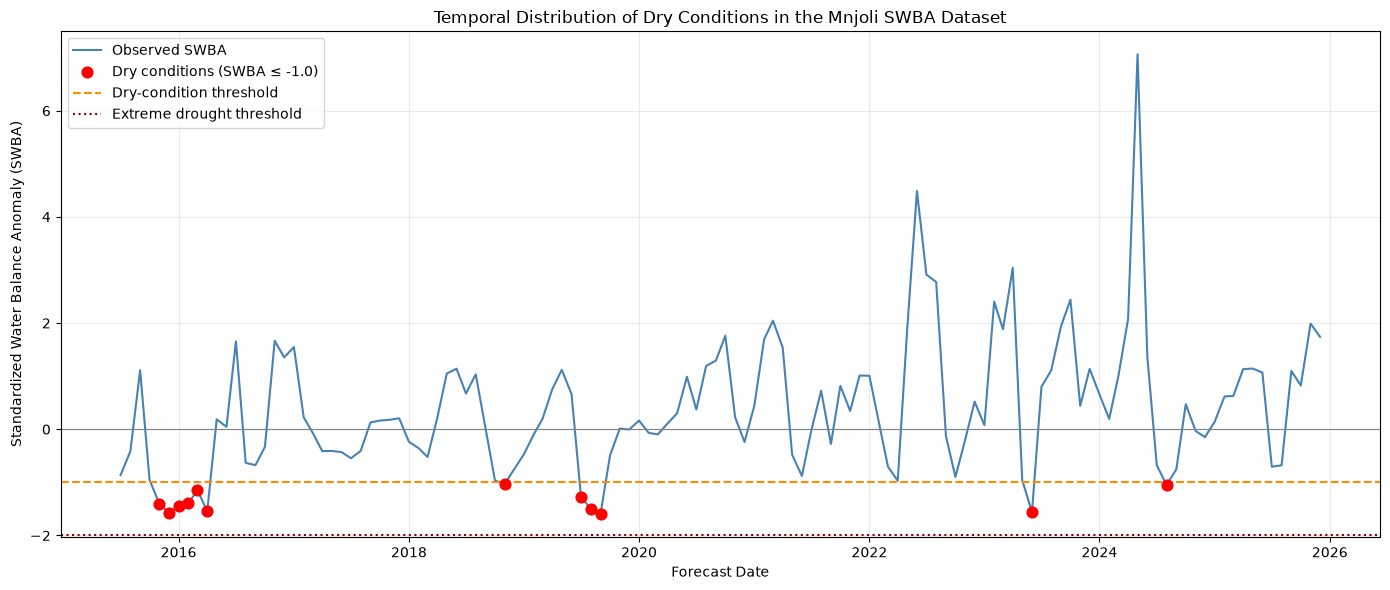

In [29]:
import matplotlib.pyplot as plt
import pandas as pd

plot_data = df_model[
    ["forecast_date", "target_t_plus_1"]
].copy()

plot_data["forecast_date"] = pd.to_datetime(
    plot_data["forecast_date"]
)

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    plot_data["forecast_date"],
    plot_data["target_t_plus_1"],
    color="steelblue",
    linewidth=1.5,
    label="Observed SWBA"
)

dry_data = plot_data[
    plot_data["target_t_plus_1"] <= -1.0
]

ax.scatter(
    dry_data["forecast_date"],
    dry_data["target_t_plus_1"],
    color="red",
    s=60,
    label="Dry conditions (SWBA ≤ -1.0)",
    zorder=3
)

ax.axhline(
    -1.0,
    color="darkorange",
    linestyle="--",
    label="Dry-condition threshold"
)

ax.axhline(
    -2.0,
    color="darkred",
    linestyle=":",
    label="Extreme drought threshold"
)

ax.axhline(
    0,
    color="gray",
    linewidth=0.8
)

ax.set_title(
    "Temporal Distribution of Dry Conditions "
    "in the Mnjoli SWBA Dataset"
)

ax.set_xlabel("Forecast Date")
ax.set_ylabel("Standardized Water Balance Anomaly (SWBA)")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [ ]:
# Independent test-set dry-condition sample-size assessment

dry_threshold = -1.0

dry_test_subset = test_results.loc[
    test_results["observed"] <= dry_threshold
].copy()

print("SUPPLEMENTARY DRY-CONDITION SAMPLE-SIZE ASSESSMENT")
print("Independent test observations:", len(test_results))
print("Observations with SWBA <= -1.0:", len(dry_test_subset))
print("Observations with SWBA <= -1.5:",
      (test_results["observed"] <= -1.5).sum())
print("Observations with SWBA <= -2.0:",
      (test_results["observed"] <= -2.0).sum())

if len(dry_test_subset) == 0:
    print("\nNo dry-condition observations were present at the selected threshold.")
elif len(dry_test_subset) == 1:
    print(
        "\nOnly one independent test observation meets the dry-condition "
        "threshold. A separate dry-only model performance comparison is "
        "therefore not reported."
    )
else:
    print(
        "\nDry-condition observations are available, but subgroup "
        "performance should be interpreted cautiously given the small sample."
    )

display(
    dry_test_subset[
        ["forecast_date", "observed"]
    ]
    .sort_values("forecast_date")
    .assign(
        observed=lambda frame: frame["observed"].round(4)
    )
)


In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

models = ["ridge_forecast", "persistence", "climatology"]

for model in models:
    actual = test_results["observed"]
    predicted = test_results[model]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    bias = np.mean(predicted - actual)

    print(f"\n{model}")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"Mean Bias: {bias:.4f}")


ridge_forecast
MAE: 0.9625
RMSE: 1.3906
Mean Bias: -0.5274

persistence
MAE: 1.0290
RMSE: 1.7568
Mean Bias: -0.0252

climatology
MAE: 1.1358
RMSE: 1.7589
Mean Bias: -0.7989


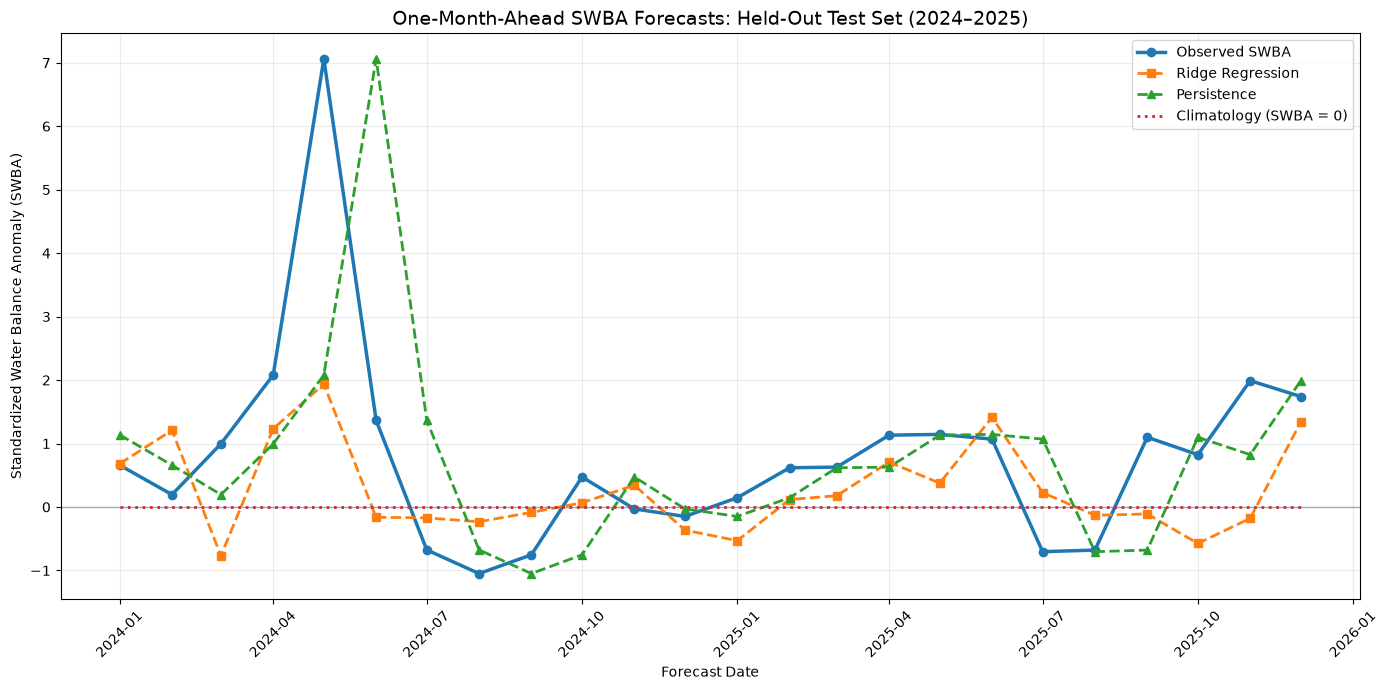

In [46]:
import matplotlib.pyplot as plt
import pandas as pd

# Sort test observations chronologically
plot_data = test_results.sort_values("forecast_date").copy()

dates = pd.to_datetime(plot_data["forecast_date"])

plt.figure(figsize=(14, 7))

plt.plot(
    dates,
    plot_data["observed"],
    marker="o",
    linewidth=2.5,
    label="Observed SWBA"
)

plt.plot(
    dates,
    plot_data["ridge_forecast"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Ridge Regression"
)

plt.plot(
    dates,
    plot_data["persistence"],
    marker="^",
    linestyle="--",
    linewidth=2,
    label="Persistence"
)

plt.plot(
    dates,
    plot_data["climatology"],
    linestyle=":",
    linewidth=2,
    label="Climatology (SWBA = 0)"
)

plt.axhline(y=0, linewidth=1, alpha=0.5)

plt.title(
    "One-Month-Ahead SWBA Forecasts: "
    "Held-Out Test Set (2024–2025)",
    fontsize=14
)

plt.xlabel("Forecast Date")
plt.ylabel("Standardized Water Balance Anomaly (SWBA)")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig("figure_test_performance.png", dpi=300, bbox_inches="tight")
plt.savefig("figure_test_performance.pdf", bbox_inches="tight")
plt.show()

In [48]:
from sklearn.metrics import r2_score

actual = test_results["observed"]

r2_ridge = r2_score(actual, test_results["ridge_forecast"])
r2_persistence = r2_score(actual, test_results["persistence"])
r2_climatology = r2_score(actual, test_results["climatology"])

print(f"Ridge Regression R²: {r2_ridge:.4f}")
print(f"Persistence R²:      {r2_persistence:.4f}")
print(f"Climatology R²:      {r2_climatology:.4f}")

Ridge Regression R²: 0.2124
Persistence R²:      -0.2570
Climatology R²:      -0.2600


In [49]:
# Calculate absolute errors for Ridge predictions
error_analysis = test_results.copy()

error_analysis["ridge_absolute_error"] = (
    error_analysis["observed"] -
    error_analysis["ridge_forecast"]
).abs()

# Sort from largest error to smallest
worst_predictions = error_analysis.sort_values(
    "ridge_absolute_error",
    ascending=False
)

display(
    worst_predictions[
        ["forecast_date", "observed",
         "ridge_forecast", "ridge_absolute_error"]
    ].head(5).round(4)
)

C:\Users\Para\AppData\Local\Temp\ipykernel_16204\645475402.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(5).round(4)


,forecast_date,observed,ridge_forecast,ridge_absolute_error
4,2024-05-01,7.0614,1.9365,5.1248
22,2025-11-01,1.9902,-0.1786,2.1688
2,2024-03-01,0.9950,-0.7691,1.7641
5,2024-06-01,1.3644,-0.1616,1.5260
21,2025-10-01,0.8245,-0.5750,1.3995


In [ ]:
# Verify the modelling-dataset date alignment around May 2024

alignment = df_model.loc[
    df_model["forecast_date"].between(
        "2024-04-01", "2024-06-01"
    ),
    ["month_date", "forecast_date", "target_t_plus_1"]
].copy()

print("Modelling dataset alignment around May 2024:")
display(alignment)

may_row = alignment.loc[
    alignment["forecast_date"] == pd.Timestamp("2024-05-01")
]

assert len(may_row) == 1
assert may_row["month_date"].iloc[0] == pd.Timestamp("2024-04-01")

print(
    "\nPASS: The May 2024 target is stored on the row with "
    "month_date April 2024 and forecast_date May 2024."
)


# 4. Interpretation and Limitations

- SWBA is a standardized water-balance anomaly relative to the
  2015-2021 calendar-month reference climatology.
- Negative SWBA indicates below-reference water balance; positive
  SWBA indicates above-reference water balance.
- The May 2024 SWBA of approximately +7.061 is an extreme positive
  anomaly relative to the historical May reference climatology.
- The May 2024 absolute three-month water balance was approximately
  -58.96 mm. A positive standardized anomaly does not mean that the
  absolute water balance was positive.
- May 2024 is retained in the primary full-period trend analysis.
  Excluding it is a diagnostic sensitivity check, not a correction
  or justification for discarding an extreme observation.
- The temporal trend is observational and does not establish
  causation or a specific climate mechanism.
- The independent test period contains 24 observations. Only one
  reaches SWBA <= -1.0, and none reaches SWBA <= -1.5 or <= -2.0.
  This limits meaningful evaluation of dry-event and extreme-drought
  detection.
- A dry-only model performance comparison is therefore not reported.
- Full-period predictions from a model fitted on pre-test data are
  not independent out-of-sample estimates.
- Independent test performance must be reported from the original
  chronological evaluation notebook.
